# 01 · EDA y calidad de datos
Objetivo: entender los datos, documentar problemas de calidad y fijar decisiones de preprocesamiento antes de modelar.

In [ ]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt

%config InlineBackend.figure_format = 'retina'

from src.data.load import load_transactions, load_stores, load_calendar
from src.data.preprocess import build_panel
plt.rcParams.update({'figure.figsize': (10, 3.6), 'axes.grid': True, 'grid.alpha': .3})
t, s, c = load_transactions(), load_stores(), load_calendar()
p = build_panel(t, s, c)
print(t.shape, s.shape, c.shape, '| periodo', t.date.min().date(), '->', t.date.max().date())
print('tiendas', t.store_id.nunique(), '| categorías', t.category.nunique(), '| series', p.groupby(['store_id','category']).ngroups)

(203958, 13) (80, 9) (425, 15) | periodo 2023-01-01 -> 2024-02-29
tiendas 80 | categorías 6 | series 480


## 1. Estructura y completitud

In [2]:
esperadas = p.shape[0]
print(f'Filas esperadas (malla completa): {esperadas:,} | observadas: {len(t):,} | ausentes: {int(p.is_missing_row.sum())}')
aus = p[p.is_missing_row].groupby('store_id').agg(desde=('date','min'), hasta=('date','max'), filas=('date','size'))
aus

Filas esperadas (malla completa): 204,000 | observadas: 203,958 | ausentes: 42


,desde,hasta,filas
store_id,,,
STR_045,2023-02-01,2023-02-02,12
STR_055,2024-02-18,2024-02-20,18
STR_064,2023-02-22,2023-02-23,12


**Hallazgo.** Los «periodos sin datos» son pocos: 3 tiendas con 2–3 días completos ausentes (42 filas, 0.02 %). No se imputan: se reincorporan a la malla con `is_missing_row` y se excluyen de entrenamiento y métricas.

## 2. Nulos por columna y por tienda

In [3]:
nulos = t.isna().mean().mul(100).round(2); nulos[nulos > 0]

cash_transactions       5.94
amount_cash             5.94
units_sold              3.00
avg_ticket              2.39
replenishment_signal    0.47
dtype: float64

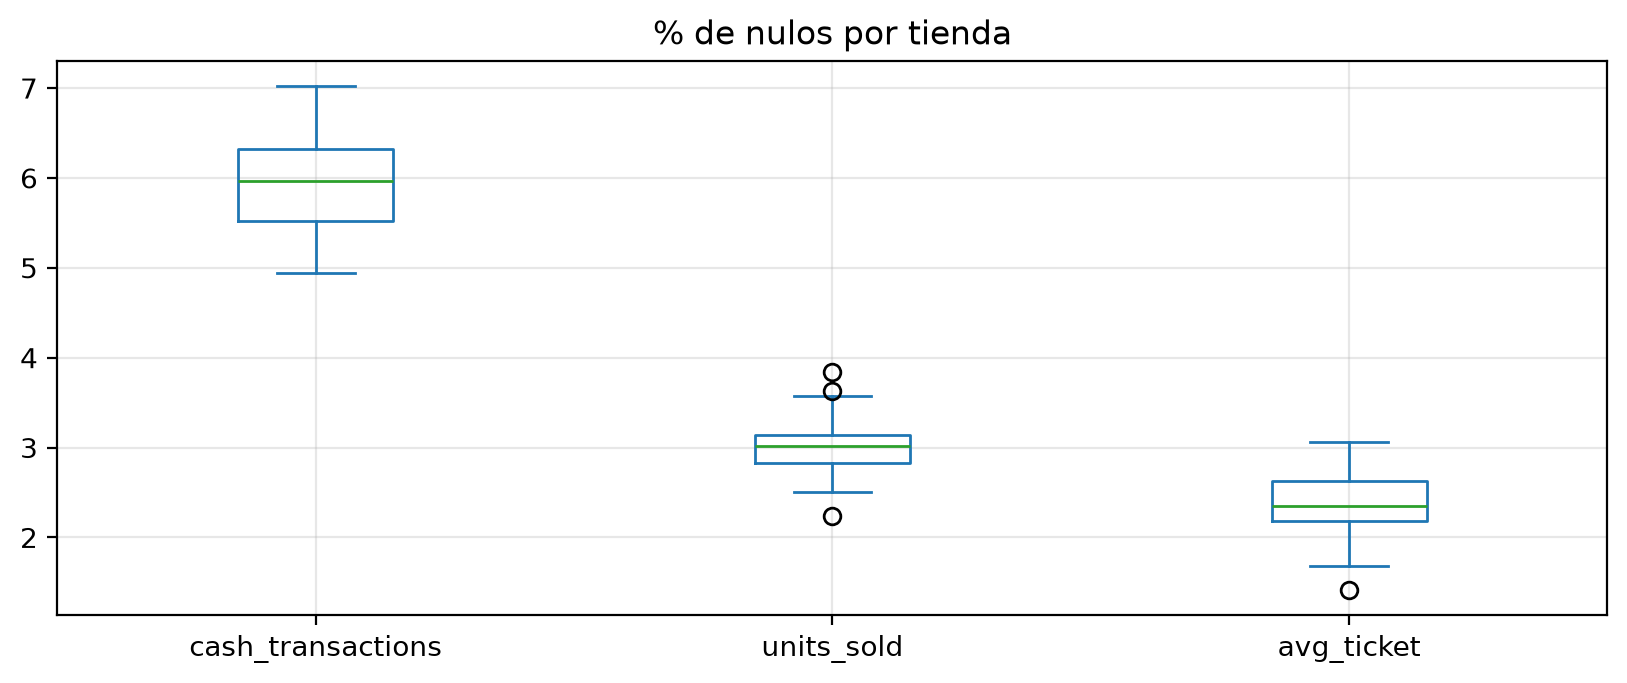

tienda-semanas con efectivo 100% nulo: 0 de 4960


In [4]:
por_tienda = t.groupby('store_id')[['cash_transactions','units_sold','avg_ticket']].apply(lambda d: d.isna().mean()*100)
ax = por_tienda.plot(kind='box', title='% de nulos por tienda'); plt.show()
# ¿hay semanas completas sin dato de efectivo en alguna tienda?
sem = t.assign(w=t.date.dt.to_period('W')).groupby(['store_id','w']).cash_transactions.apply(lambda x: x.isna().mean())
print('tienda-semanas con efectivo 100% nulo:', int((sem == 1).sum()), 'de', len(sem))

**Hallazgo.** Los nulos de `cash_transactions`/`amount_cash` (5.9 %), `units_sold` (3.0 %) y `avg_ticket` (2.4 %) están dispersos de forma homogénea entre tiendas (máx. ~7 % por tienda): son fallas puntuales, no apagones. `amount_total` y `amount_card` no tienen nulos.

**Decisión (con criterio de negocio).**
| Columna | Tratamiento | Razón |
|---|---|---|
| `amount_total` | target, sin nulos | completa y = efectivo + tarjeta exacto |
| `cash_*`, `avg_ticket`, `units_sold` | se mantienen NaN + bandera | son del mismo día que se pronostica: no existen al predecir, imputarlas no mejora el modelo |
| filas ausentes | NaN + `is_missing_row` | imputar el target crearía datos que el modelo aprendería e inflaría métricas |
| `replenishment_signal` | se descarta | ver §7 |

## 3. Distribución de ventas por segmento

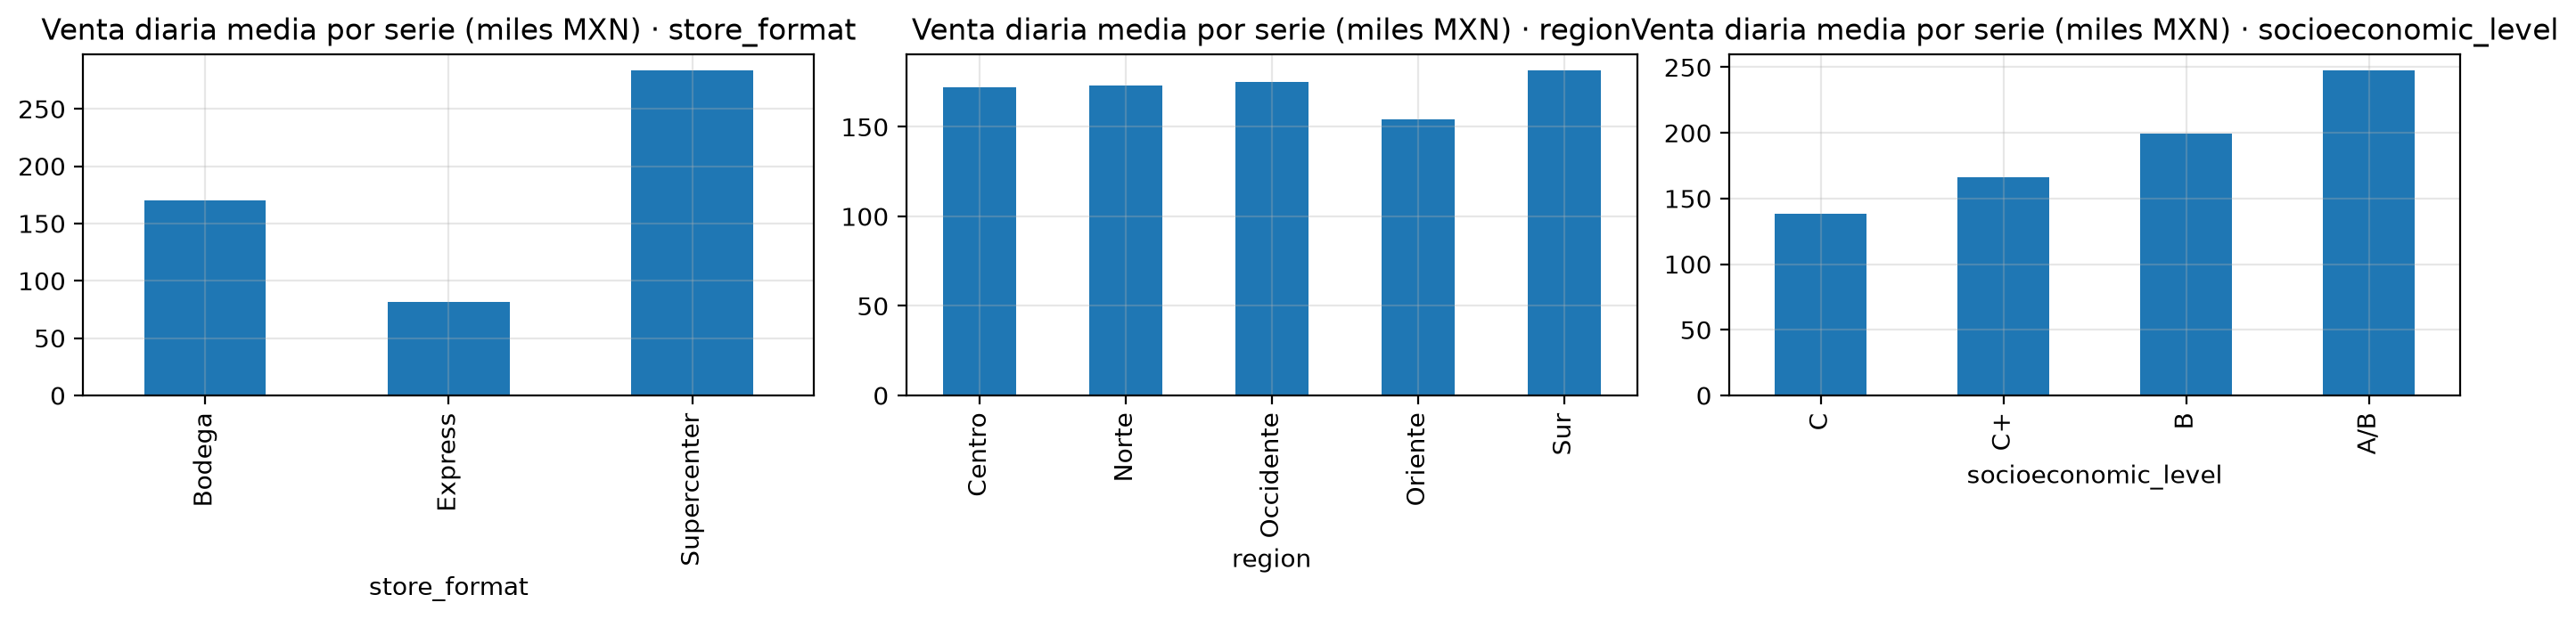

,mean,median,sum,share
category,,,,
Abarrotes,257363.0,203838.0,8.748550e+09,0.251
Bebidas,131808.0,104335.0,4.480565e+09,0.129
Cuidado_Personal,107984.0,85540.0,3.670696e+09,0.106
Electronica,185222.0,147017.0,6.296238e+09,0.181
Hogar,172425.0,136760.0,5.861226e+09,0.168
Ropa,168686.0,134074.0,5.734136e+09,0.165


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, col in zip(ax, ['store_format','region','socioeconomic_level']):
    p.groupby(col, observed=True).amount_total.mean().div(1e3).plot(kind='bar', ax=a, title=f'Venta diaria media por serie (miles MXN) · {col}')
plt.tight_layout(); plt.show()
p.groupby('category').amount_total.agg(['mean','median','sum']).round(0).assign(share=lambda d: (d['sum']/d['sum'].sum()).round(3))

In [6]:
print(s.groupby(['store_format']).agg(n=('store_id','size'), sqm=('size_sqm','median'), cajas=('num_checkouts','median')))
print(np.log(p.amount_total).groupby(p.store_id).mean().pipe(lambda x: f'CV del nivel entre tiendas (log): {x.std()/x.mean():.2%}'))

               n      sqm  cajas
store_format                    
Bodega        35   5442.0   14.0
Express       25   1975.0    7.0
Supercenter   20  11875.0   29.0
CV del nivel entre tiendas (log): 4.47%


**Hallazgo.** El nivel de venta difiere claramente por categoría (Abarrotes ≈ 25 % del monto) y por formato (el tamaño mediano va de ~2 mil m² en Express a ~12 mil en Supercenter). Hay mucha heterogeneidad de escala entre series, por lo que las métricas deben ser relativas (WAPE/sesgo), no RMSE ni R² globales, que solo reflejan la diferencia de tamaño entre tiendas.

## 4. Dinámica temporal: estacionalidad semanal y eventos

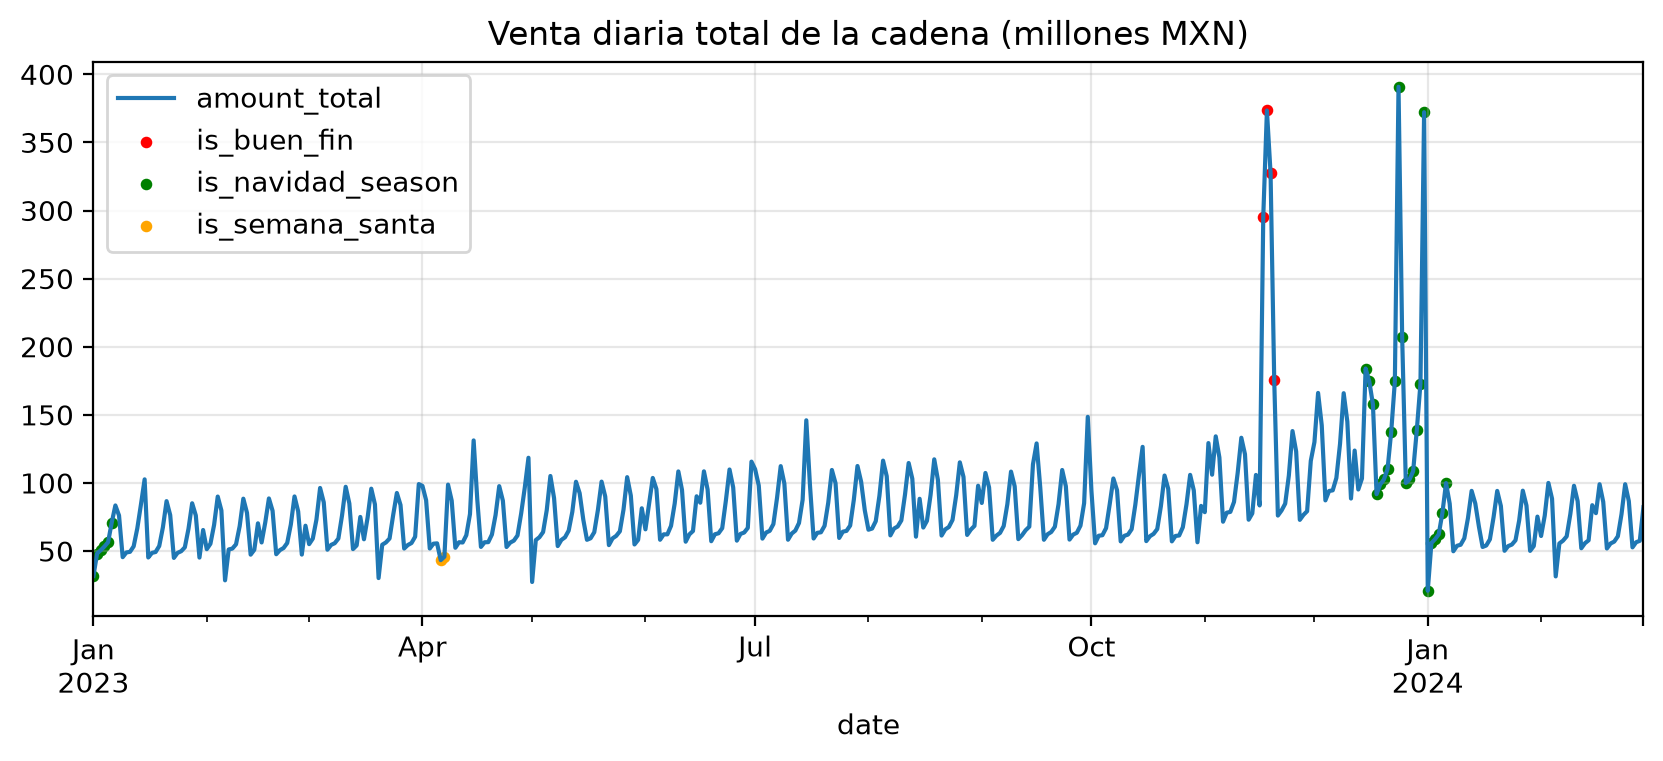

day_of_week
0    0.732
1    0.773
2    0.795
3    0.859
4    1.107
5    1.409
6    1.324
Name: amount_total, dtype: float64

In [7]:
d = p.groupby('date').amount_total.sum() / 1e6
ax = d.plot(title='Venta diaria total de la cadena (millones MXN)')
for col, color in [('is_buen_fin','red'), ('is_navidad_season','green'), ('is_semana_santa','orange')]:
    f = c.loc[c[col], 'date']; ax.scatter(f.values, d.reindex(f).values, s=10, color=color, label=col)
ax.legend(); plt.show()
dow = p.groupby('day_of_week').amount_total.mean(); (dow/dow.mean()).round(3)

In [8]:
sem = d.resample('W').sum(); (sem / sem['2023-09-04':'2023-09-30'].mean()).round(2).loc['2023-10-22':'2024-01-31']

date
2023-10-22    0.95
2023-10-29    0.95
2023-11-05    1.26
2023-11-12    1.21
2023-11-19    2.39
2023-11-26    1.40
2023-12-03    1.40
2023-12-10    1.46
2023-12-17    1.66
2023-12-24    1.98
2023-12-31    2.15
2024-01-07    0.82
2024-01-14    0.84
2024-01-21    0.87
2024-01-28    0.83
Freq: W-SUN, Name: amount_total, dtype: float64

**Hallazgo.** Hay fuerte efecto de día de la semana y dos eventos dominantes: **Buen Fin** y **Navidad**, con saltos de la cadena de más del doble en las semanas del evento, seguidos de una caída en enero. Cada evento aparece **una sola vez** en 14 meses, así que ningún modelo entrenado antes del evento puede aprender su magnitud: se evaluarán aparte de los periodos regulares y se reportarán como prueba de estrés.

## 5. Promociones: frecuencia, asignación y patrón

In [9]:
print('% filas con promoción:', round(p.has_promotion.mean()*100, 2))
rows = []
for col in ['day_of_week','is_payday','is_buen_fin','is_navidad_season','store_format','region','socioeconomic_level','category']:
    g = p.groupby(col, observed=True).has_promotion.mean().mul(100).round(1)
    rows.append(pd.DataFrame({'variable': col, 'nivel': g.index.astype(str), '% promo': g.values}))
pd.concat(rows).set_index(['variable','nivel'])

% filas con promoción: 19.97


% promo
variable            nivel                    
day_of_week         0                    20.3
                    1                    19.7
                    2                    19.9
                    3                    20.0
                    4                    19.8
                    5                    20.0
                    6                    20.1
is_payday           False                20.0
                    True                 20.2
is_buen_fin         False                20.0
                    True                 20.3
is_navidad_season   False                20.0
                    True                 19.6
store_format        Bodega               19.9
                    Express              20.0
                    Supercenter          20.1
region              Centro               20.0
                    Norte                20.1
                    Occidente            19.8
                    Oriente              20.2
                    Sur                  19.7
socioeconomic_level C                    19.9
                    C+                   20.3
                    B                    19.7
                    A/B                  19.6
category            Abarrotes            19.9
                    Bebidas              20.0
                    Cuidado_Personal     19.9
                    Electronica          20.0
                    Hogar                20.2
                    Ropa                 19.9

autocorrelación lag-1 de la promoción: -0.002 | duración media de una promo: 1.25 días | % de promos de 1 día: 80%


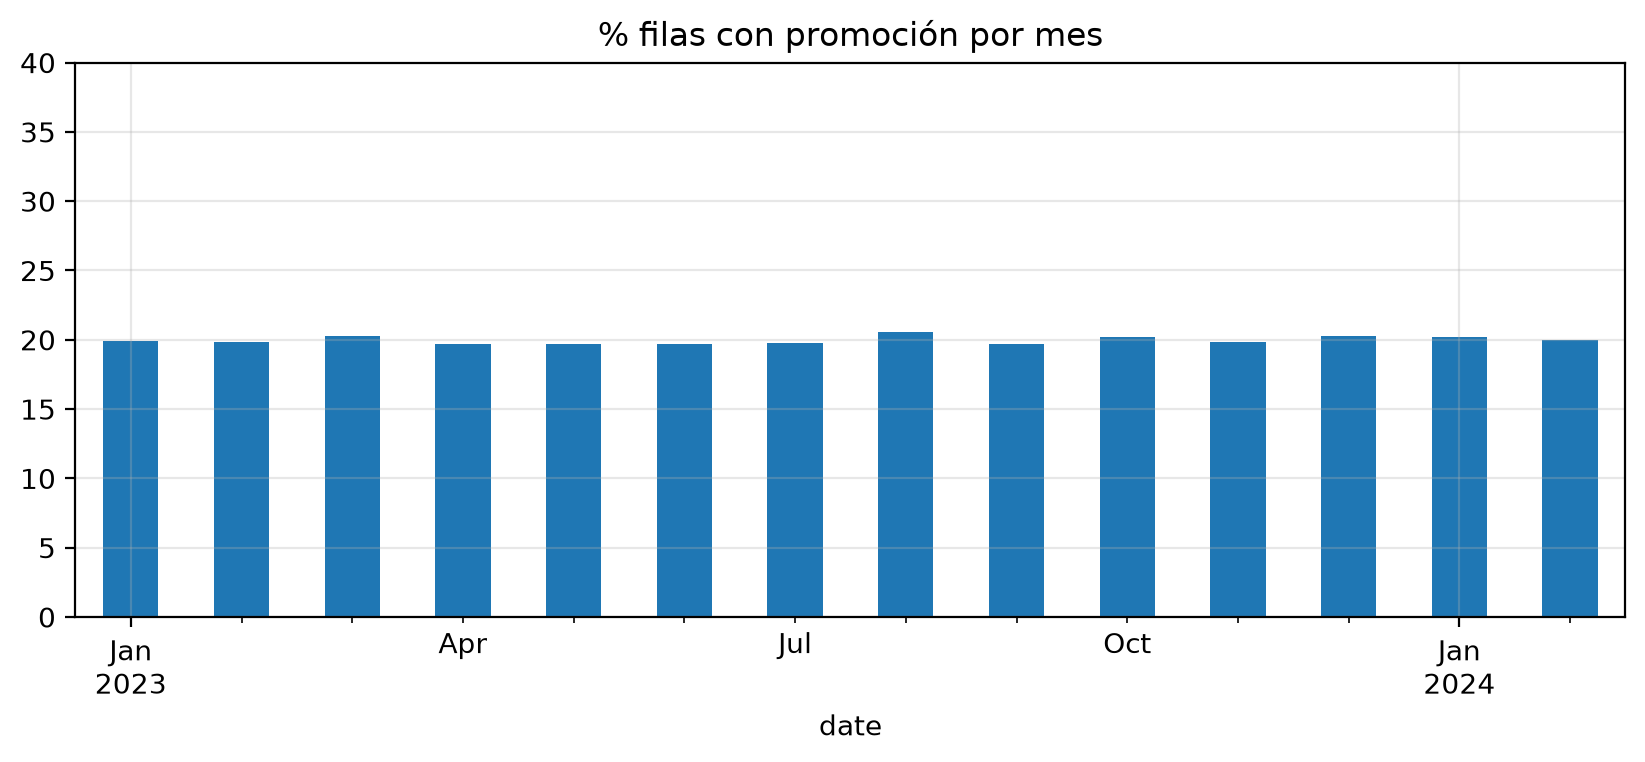

In [10]:
q = p.sort_values(['store_id','category','date'])
ac = q.groupby(['store_id','category']).has_promotion.apply(lambda x: x.autocorr(1)).mean()
runs = (q.groupby(['store_id','category']).has_promotion
          .apply(lambda x: x.groupby((x != x.shift()).cumsum()).agg(['first','size']).query('first == 1')['size']))
print(f'autocorrelación lag-1 de la promoción: {ac:.3f} | duración media de una promo: {runs.mean():.2f} días | % de promos de 1 día: {(runs==1).mean():.0%}')
m = p.groupby(p.date.dt.to_period('M')).has_promotion.mean().mul(100); m.plot(kind='bar', title='% filas con promoción por mes'); plt.ylim(0, 40); plt.show()

**Hallazgo clave para la Capa 2.** La promoción cubre ≈20 % de las filas en *todos* los segmentos, meses, días de la semana, quincenas y eventos, sin autocorrelación (≈0) y con duración típica de 1 día. Eso es lo que se vería con una asignación **aleatoria** (Bernoulli ≈ 0.2 por serie-día), no con una decisión comercial dirigida. Implicaciones:
- El riesgo de sesgo de selección (planteado en el plan) es bajo; aun así el diseño controla por efectos fijos y calendario y se documenta como supuesto.
- No hay periodos prolongados de promoción: el efecto es un efecto «de día»; se probarán rezagos/adelantos del tratamiento en la Fase 4 (anticipación y canibalización).

## 6. ¿Qué efecto aparente tiene la promoción? Transacciones vs. monto

In [11]:
q = p.dropna(subset=['amount_total']).copy()
for v in ['amount_total','total_transactions']:
    q['l'] = np.log(q[v].clip(lower=1)); q['lc'] = q.l - q.groupby(['store_id','category']).l.transform('mean')
    dif = q[q.has_promotion==1].lc.mean() - q[q.has_promotion==0].lc.mean()
    print(f'{v:20s} efecto aparente de la promo: {np.expm1(dif):+.2%}')
chk = q.dropna(subset=['tx_inflated']).groupby('has_promotion').tx_inflated.mean()
print('\n% filas donde total_transactions != efectivo + tarjeta:'); print(chk.mul(100).round(1))

amount_total         efecto aparente de la promo: +0.03%
total_transactions   efecto aparente de la promo: +22.15%

% filas donde total_transactions != efectivo + tarjeta:
has_promotion
0      0.0
1    100.0
Name: tx_inflated, dtype: float64


**Hallazgo.** `total_transactions` sube ~22 % en días con promoción **pero el monto cobrado no cambia** (~0 %). Además `total_transactions ≠ efectivo + tarjeta` en el 100 % de las filas con promoción donde se puede verificar y en 0 % de las demás: el conteo está inflado. Por eso **el target y el uplift se miden sobre `amount_total`** y no sobre transacciones.

## 7. `replenishment_signal`: ¿es válida como feature?

In [12]:
w = t.sort_values(['store_id','category','date']).copy()
g = w.groupby(['store_id','category']).total_transactions
w['ma'] = sum(g.shift(k) for k in range(-1, 6)) / 7          # ventana [t-5, t+1]
ok = w.dropna(subset=['ma','replenishment_signal'])
print(f"coincide con el promedio de total_transactions en [t-5, t+1]: {(np.abs(ok.ma - ok.replenishment_signal) <= 1).mean():.2%}")
print('fechas con nulo (primeras):', t[t.replenishment_signal.isna()].date.value_counts().sort_index().head(3).to_dict())

coincide con el promedio de total_transactions en [t-5, t+1]: 99.76%
fechas con nulo (primeras): {Timestamp('2023-01-01 00:00:00'): 480, Timestamp('2023-01-02 00:00:00'): 480}


**Hallazgo (fuga de información).** La señal es el promedio móvil de `total_transactions` de los 7 días `[t−5, t+1]`: contiene la demanda del día que se quiere predecir y la del siguiente. Usarla haría que las métricas fueran artificialmente buenas. **Se excluye** (sin importar el rezago) y sus nulos no se imputan. Sus nulos están al *inicio* del periodo y no al final como indica el diccionario.

## 8. Outliers

In [13]:
q = p.dropna(subset=['amount_total']).copy(); q['l'] = np.log(q.amount_total)
q['res'] = q.l - q.groupby(['store_id','category','day_of_week']).l.transform('median')
q['evento'] = q.is_buen_fin | q.is_navidad_season
print('|residuo| > 1 (en log) por tipo de día:'); print(q.assign(out=q.res.abs() > 1).groupby('evento').out.agg(['sum','mean']))
print('mínimo amount_total:', round(q.amount_total.min()), '| ceros:', int((q.amount_total==0).sum()))

|residuo| > 1 (en log) por tipo de día:
         sum      mean
evento                
False    180  0.000957
True    3563  0.224937
mínimo amount_total: 6922 | ceros: 0


**Hallazgo.** No hay ceros ni negativos. Los valores extremos se concentran en eventos y son demanda real, no errores: no se recortan ni se eliminan. Se modelan con calendario y se evalúan por separado.

## 9. Conclusiones y decisiones
1. **Target:** `amount_total` (sin nulos, consistente con efectivo + tarjeta).
2. **No imputar** el target ni descartar filas; la malla se completa con banderas. Los nulos de variables del mismo día no pueden ser features.
3. **Excluir `replenishment_signal`** (fuga) y **no usar `total_transactions`** como medida de promoción (inflado).
4. **Métricas relativas** (WAPE, sesgo) y evaluación en **tienda × categoría × semana**; periodos regulares y eventos por separado.
5. **Features** del target con rezago mínimo = horizonte (14 días) para evitar fuga temporal.
6. **Promoción** con apariencia de aleatoria y efecto aparente ≈ 0 en monto: la Capa 2 debe reportar el efecto con intervalo de confianza y probar heterogeneidad, sin asumir que es positivo.

## Notebooks complementarios
- **`02_eda_complementario.ipynb`:** pruebas formales de nulos (MCAR), consistencias monto/transacciones/ticket, calendario, atributos de tienda, aleatoriedad de la promoción y piso de ruido por granularidad.
- **`03_auditoria_replenishment_signal.ipynb`:** auditoría completa de la fuga de información de `replenishment_signal` (correlación cruzada, reconstrucción exacta e indirecta y prueba predictiva).